<a href="https://colab.research.google.com/github/Bishesh-P/Drowsiness-Detection-Using-YOLO/blob/main/Drowsiness_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install torch

In [ ]:
!git clone https://github.com/ultralytics/yolov5

Cloning into 'yolov5'...
remote: Enumerating objects: 18806, done.
remote: Counting objects: 100% (358/358), done.
remote: Compressing objects: 100% (215/215), done.
remote: Total 18806 (delta 298), reused 143 (delta 143), pack-reused 18448 (from 2)
Receiving objects: 100% (18806/18806), 17.75 MiB | 19.20 MiB/s, done.
Resolving deltas: 100% (12819/12819), done.


In [ ]:
!cd yolov5/
!pip install -r requirements.txt

/bin/bash: line 1: cd: yolov5/: No such file or directory
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 12.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]


In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import cv2

In [50]:
model = torch.hub.load('ultralytics/yolov5', 'yolov5m')

YOLOv5 🚀 2026-10-29 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)



Using cache found in /root/.cache/torch/hub/ultralytics_yolov5_master


100%|██████████| 40.8M/40.8M [00:00<00:00, 101MB/s] 

Fusing layers... 
YOLOv5m summary: 168 layers, 21,172,173 parameters, 0 gradients, 48.9 GFLOPs
Adding AutoShape... 


In [51]:
model

AutoShape(
  (model): DetectMultiBackend(
    (model): DetectionModel(
      (model): Sequential(
        (0): Conv(
          (conv): Conv2d(3, 48, kernel_size=(6, 6), stride=(2, 2), padding=(2, 2))
          (act): SiLU(inplace=True)
        )
        (1): Conv(
          (conv): Conv2d(48, 96, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
          (act): SiLU(inplace=True)
        )
        (2): C3(
          (cv1): Conv(
            (conv): Conv2d(96, 48, kernel_size=(1, 1), stride=(1, 1))
            (act): SiLU(inplace=True)
          )
          (cv2): Conv(
            (conv): Conv2d(96, 48, kernel_size=(1, 1), stride=(1, 1))
            (act): SiLU(inplace=True)
          )
          (cv3): Conv(
            (conv): Conv2d(96, 96, kernel_size=(1, 1), stride=(1, 1))
            (act): SiLU(inplace=True)
          )
          (m): Sequential(
            (0): Bottleneck(
              (cv1): Conv(
                (conv): Conv2d(48, 48, kernel_size=(1, 1), stride=(1, 1))
  

# Checking up Yolov5


In [52]:
img = 'https://ultralytics.com/images/zidane.jpg'

In [53]:
result = model(img)

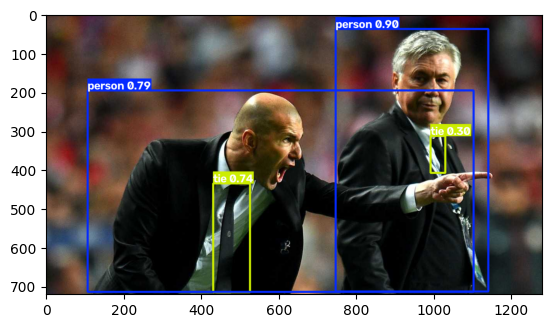

In [54]:
plt.imshow(np.squeeze(result.render()))
plt.show()

# Real Time Video Capture Test


In [55]:
import torch, cv2, numpy as np
from base64 import b64decode, b64encode
from IPython.display import display, Javascript, HTML, clear_output
from google.colab.output import eval_js

# Load model
model = torch.hub.load('ultralytics/yolov5', 'yolov5s', trust_repo=True)

# HTML & JS template that creates a persistent image tag and registers helper functions globally
html_layout = HTML('''
<div style="display: flex; flex-direction: column; align-items: center;">
  <img id="webcam_display" style="width: 640px; height: 480px; border: 2px solid #555; border-radius: 8px;" />
</div>
''')

js_helpers = Javascript('''
async function startCam() {
  if (window.cam) return;
  const video = document.createElement('video');
  video.style.display = 'none';
  document.body.appendChild(video);
  const stream = await navigator.mediaDevices.getUserMedia({video: true});
  video.srcObject = stream;
  await video.play();
  const canvas = document.createElement('canvas');
  canvas.width = 640; canvas.height = 480;
  window.cam = {video, stream, canvas};
}

function grab() {
  if (!window.cam) return null;
  const {video, canvas} = window.cam;
  canvas.getContext('2d').drawImage(video, 0, 0, 640, 480);
  return canvas.toDataURL('image/jpeg', 0.8);
}

function updateDisplay(base64Image) {
  const img = document.getElementById("webcam_display");
  if (img) {
    img.src = base64Image;
  }
}

function stopCam() {
  if (window.cam && window.cam.stream) {
    window.cam.stream.getTracks().forEach(t => t.stop());
    window.cam = null;
  }
}

window.startCam = startCam;
window.grab = grab;
window.updateDisplay = updateDisplay;
window.stopCam = stopCam;
''')

# Render layout and load persistent JS functions
display(html_layout)
display(js_helpers)

# Start Camera
eval_js('startCam()')

try:
    while True:
        # Grab frame via JavaScript
        data = eval_js('grab()')
        if not data:
            continue

        # Decode base64 image data to OpenCV image
        frame = cv2.imdecode(np.frombuffer(b64decode(data.split(',')[1]), np.uint8), 1)

        # Run YOLO inference (convert BGR to RGB)
        results = model(frame[..., ::-1])
        annotated = np.squeeze(results.render())[..., ::-1]

        # Convert annotated frame back to jpeg base64
        _, buffer = cv2.imencode('.jpg', annotated)
        annotated_b64 = b64encode(buffer).decode('utf-8')
        annotated_data_url = f"data:image/jpeg;base64,{annotated_b64}"

        # Update the persistent image tag directly in JS without clearing output
        eval_js(f'updateDisplay("{annotated_data_url}")')

except KeyboardInterrupt:
    print("Stream stopped by user.")
finally:
    try:
        eval_js('stopCam()')
    except Exception:
        pass

YOLOv5 🚀 2026-10-29 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)

Fusing layers... 
YOLOv5s summary: 124 layers, 7,225,885 parameters, 0 gradients, 16.4 GFLOPs
Adding AutoShape... 


Using cache found in /root/.cache/torch/hub/ultralytics_yolov5_master


<IPython.core.display.Javascript object>

Stream stopped by user.


# Trainning Data From Scratch

In [57]:
import torch, cv2, os, time, uuid, glob, numpy as np
from base64 import b64decode
from IPython.display import display, Javascript, clear_output
from google.colab.output import eval_js
from google.colab.patches import cv2_imshow


In [58]:
print(torch.__version__, torch.cuda.is_available())

2.11.0+cu130 True


In [ ]:
display(Javascript('''
async function startCam() {
  const video = document.createElement('video');
  video.style.display = 'none';
  document.body.appendChild(video);
  const stream = await navigator.mediaDevices.getUserMedia({video: true});
  video.srcObject = stream;
  await video.play();
  const canvas = document.createElement('canvas');
  canvas.width = 640; canvas.height = 480;
  window.cam = {video, stream, canvas};
}
function grab() {
  const {video, canvas} = window.cam;
  canvas.getContext('2d').drawImage(video, 0, 0, 640, 480);
  return canvas.toDataURL('image/jpeg', 0.9);
}
function stopCam() { window.cam.stream.getTracks().forEach(t => t.stop()); }
'''))

def get_frame():
    data = eval_js('grab()')
    return cv2.imdecode(np.frombuffer(b64decode(data.split(',')[1]), np.uint8), 1)

In [ ]:
IMAGES_PATH = '/content/data/raw'
labels = ['awake', 'drowsy']
number_imgs = 20          # the tutorial's 5 is only a demo; aim for 100+ per class
os.makedirs(IMAGES_PATH, exist_ok=True)

eval_js('startCam()')
for label in labels:
    print(f'Get ready: "{label}" starts in 5s')
    time.sleep(5)
    for i in range(number_imgs):
        frame = get_frame()
        cv2.imwrite(os.path.join(IMAGES_PATH, f'{label}.{uuid.uuid1()}.jpg'), frame)
        time.sleep(0.5)    # move your head slightly and vary the lighting between shots
    print(f'Done {label}')
eval_js('stopCam()')